# Chain of thought and response triggers

*Course demo, completed. Follows [6](6-prompts-decoding-and-synthetic-data.ipynb), which explains the decoding parameters used here and the "virtuous feedback loop" this notebook tests. The original course demo (`demo_cot_and_triggers.ipynb`) is not included here; the table below lists what I changed in it.*

**The question.** Notebook 6 showed that every token a model writes becomes part of its own input: $P(y_t \mid X, y_1, \dots, y_{t-1})$. If the model writes the arithmetic of a word problem *before* the answer, the answer token is conditioned on that arithmetic. If it writes the answer first, the answer has nothing to lean on, and any reasoning that follows can only justify it after the fact. This notebook tests that on Qwen 2 1.5B Instruct, a small model (see *Why this model* below), with five prompts for the same question:

| # | Prompt | Where the reasoning ends up |
|---|---|---|
| 1 | User prompt only | Up to the model |
| 2 | System prompt: **answer first**, then reasoning | After the answer |
| 3 | System prompt: **reasoning first**, then answer | Before the answer |
| 4 | Response trigger `A: Let's think step by step:` (Kojima et al., 2022) | Before the answer |
| 5 | Response trigger `A:` | Up to the model |

The task has a known numeric answer, so each response is checked by code (Part 3 of notebook 6). After running the course's single question, I repeat it on 20 random variants of the same problem to see whether the differences hold up.

**What I changed from the course notebook, and why**

| Course version | Problem | This notebook |
|---|---|---|
| `POST https://api.together.xyz/inference` | Together's legacy endpoint | `POST /v1/completions` (and `/v1/chat/completions` for comparison) |
| The trigger is appended to `inst_prompt`, but only `messages` is sent | **The trigger never reached the model**, so prompts 4 and 5 were identical to prompt 1 | The prompt is built with the model's chat template and the trigger is placed at the start of the assistant's turn, so the model continues from it |
| `[INST]`, `<<SYS>>` markers | These are Llama **2**'s template; other models use different special tokens and would read them as plain text | ChatML tokens (`<|im_start|>`, `<|im_end|>`), the format Qwen 2 was trained on; the `<<SYS>>` wrapper is dropped from the system prompt |
| `meta-llama/Llama-3.3-70B-Instruct-Turbo-Free` | The free endpoint has been retired, and Together now serves no Llama model without a paid dedicated endpoint | `arize-ai/qwen-2-1.5b-instruct`, set in one place below |
| Results judged by reading | | The final number is extracted and compared with the true answer |

**Why this model.** In November 2026 the models Together serves on demand fall into two groups. Most are reasoning models: they think internally before answering (they spent 16 to 80 hidden tokens to answer "What is 17 × 3?"), so they reason step by step whatever the prompt says, and the comparison below would measure nothing. Of the models that answer directly, Qwen 2 1.5B Instruct has a published chat template, which the raw prompt below needs. A small model is also closer to the setting of the 2022 papers, where the prompt made a large difference.

# System setup

In [1]:
import os
import random
import re
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, SECONDARY, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight", "font.size": 10,
        "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
        "axes.edgecolor": "#c3c2b7", "axes.labelcolor": SECONDARY,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
        "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "legend.frameon": False,
    }
)
os.makedirs("assets", exist_ok=True)

In [2]:
# The key is read from the environment, or from a local .env file (ignored by git). It is never written into the notebook.
def load_together_key():
    key = os.getenv("TOGETHER_API_KEY")
    if not key and os.path.exists(".env"):
        for line in open(".env"):
            if line.strip().startswith("TOGETHER_API_KEY="):
                key = line.split("=", 1)[1].strip().strip('"').strip("'")
    return key


def together_key_works(key):
    """One cheap call to list models: True if Together accepts the key."""
    if not key:
        return False
    try:
        r = requests.get("https://api.together.xyz/v1/models", headers={"Authorization": f"Bearer {key}"}, timeout=20)
    except requests.RequestException as e:
        print("Could not reach Together AI:", e)
        return False
    if r.status_code == 401:
        print("Together AI rejected the key (401). Use the full secret key (it starts with 'tgp_v1_'), "
              "not the key ID shown in the dashboard list ('key_...'), then restart the kernel.")
    return r.ok


TOGETHER_API_KEY = load_together_key()
assert together_key_works(TOGETHER_API_KEY), "No working TOGETHER_API_KEY: see the message above."
print("Together AI key found:", TOGETHER_API_KEY[:4] + "..." + f" ({len(TOGETHER_API_KEY)} characters)")

Together AI key found: tgp_... (50 characters)


In [3]:
BASE_URL = "https://api.together.xyz/v1"
MODEL = "arize-ai/qwen-2-1.5b-instruct"   # Qwen 2 1.5B Instruct, served by Together

In [4]:
# Decoding parameters (see notebook 6, Part 2). Greedy decoding, so differences come from the prompt.
TEMPERATURE = 0.0
MAX_TOKENS = 512
TOP_P = 1.0
TOP_K = 50
REPETITION_PENALTY = 1.0

# ChatML, Qwen 2's chat template. Each turn is: <|im_start|>role\n content <|im_end|>\n
def turn(role, content):
    return f"<|im_start|>{role}\n{content}<|im_end|>\n"


STOP = ["<|im_end|>", "<|endoftext|>"]

In [5]:
def post(path, payload, retries=5):
    """POST to Together AI, waiting and retrying on rate limits."""
    for attempt in range(retries):
        r = requests.post(f"{BASE_URL}/{path}", json=payload, timeout=120,
                          headers={"Authorization": f"Bearer {TOGETHER_API_KEY}", "Content-Type": "application/json"})
        if r.status_code == 429 or r.status_code >= 500:
            time.sleep(2 ** attempt)
            continue
        if not r.ok:
            raise RuntimeError(f"{r.status_code}: {r.text[:300]}")
        return r.json()
    r.raise_for_status()


def query_together_endpoint(prompt):
    """Raw completion: the model continues the exact string it is given, special tokens included."""
    response = post("completions", {
        "model": MODEL,
        "prompt": prompt,
        "max_tokens": MAX_TOKENS,
        "temperature": TEMPERATURE,
        "top_p": TOP_P,
        "top_k": TOP_K,
        "repetition_penalty": REPETITION_PENALTY,
        "stop": STOP,
        "stream": False,
    })
    choice = response["choices"][0]
    return choice["text"], response.get("usage", {}).get("completion_tokens")

## Helper functions

`query_model` builds the full ChatML prompt by hand. The trigger, if any, is written **after** the assistant header, so from the model's point of view it has already started its answer with those words and continues from there. This is the "response trigger" of the course: it seeds the first tokens of $Y$, and every later token is conditioned on them.

In [6]:
def build_prompt(user_prompt, system_prompt=None, trigger=None):
    system_prompt = system_prompt or "You are a helpful assistant."
    return (turn("system", system_prompt)
            + turn("user", user_prompt)
            + "<|im_start|>assistant\n" + (trigger.lstrip("\n") if trigger else ""))


def query_model(user_prompt, system_prompt=None, trigger=None, verbose=True):
    prompt = build_prompt(user_prompt, system_prompt, trigger)
    generation, n_tokens = query_together_endpoint(prompt)
    if verbose:
        print(f"*** Full prompt sent to the model ***\n{prompt}")
        print(f"\n*** Generation ({n_tokens} tokens) ***\n{generation}")
    return generation

**Check that the template is right.** If the hand-built prompt matches what Together's chat endpoint does internally, the two should give the same greedy answer to a plain question.

In [7]:
check_q = "In one sentence: what is the capital of Australia?"
raw_answer, _ = query_together_endpoint(build_prompt(check_q))
chat_answer = post("chat/completions", {
    "model": MODEL, "max_tokens": 60, "temperature": 0.0,
    "messages": [{"role": "system", "content": "You are a helpful assistant."}, {"role": "user", "content": check_q}],
})["choices"][0]["message"]["content"]
print("raw completion :", raw_answer.strip())
print("chat endpoint  :", chat_answer.strip())
print("identical      :", raw_answer.strip() == chat_answer.strip())

raw completion : The capital of Australia is Canberra.
chat endpoint  : The capital of Australia is Canberra.
identical      : True


## System prompts

In [8]:
ANSWER_STAGE = "Provide the direct answer to the user question."
REASONING_STAGE = "Describe the step by step reasoning to find the answer."

In [9]:
# System prompt can be constructed in two ways:
# 1) Answering the question first or
# 2) Providing the reasoning first

# Similar ablation performed in "Chain-of-Thought Prompting Elicits Reasoning in Large Language Models"
# https://arxiv.org/pdf/2201.11903.pdf
SYSTEM_PROMPT_TEMPLATE = """Answer the user's question using the following format:
1) {stage_1}
2) {stage_2}"""

## Response triggers

In [10]:
# Chain of thought trigger from "Large Language Models are Zero-Shot Reasoners"
# https://arxiv.org/abs/2205.11916
COT_TRIGGER = "\n\nA: Let's think step by step:"
A_TRIGGER = "\n\nA:"

## User prompt for our task

In [11]:
user_prompt_template = "Q: Llama 2 has a context window of {atten_window} tokens. \
If we are reserving {max_token} of them for the LLM response, \
the system prompt uses {sys_prompt_len}, \
the chain of thought trigger uses only {trigger_len}, \
and finally the conversational history uses {convo_history_len}, \
how many can we use for the user prompt?"

In [12]:
atten_window = 4096
max_token = 512
sys_prompt_len = 124
trigger_len = 11
convo_history_len = 390

user_prompt = user_prompt_template.format(
    atten_window=atten_window,
    max_token=max_token,
    sys_prompt_len=sys_prompt_len,
    trigger_len=trigger_len,
    convo_history_len=convo_history_len
)

In [13]:
desired_numeric_answer = atten_window - max_token - sys_prompt_len - trigger_len - convo_history_len
print(f"{atten_window} - {max_token} - {sys_prompt_len} - {trigger_len} - {convo_history_len} = {desired_numeric_answer}")

4096 - 512 - 124 - 11 - 390 = 3059


**Scoring.** Each strategy is scored on the number the model **commits to**:

- for answer-first (prompt 2), the first number it states that is not one of the five numbers in the question, since that is the answer given before any reasoning;
- for every other prompt, the last number in the response, which is where a worked answer ends.

Thousands separators are removed ("3,059" counts as 3059).

A second score separates **setting the problem up** from **doing the arithmetic**. A response has the right **setup** if it contains an arithmetic expression that evaluates to the true answer, for example `4096 - 512 - 124 - 11 - 390` or `4096 - (512 + 124 + 11 + 390)`, whatever number it then writes after the `=`. Python evaluates the expression; the model's own result is ignored. A small model can know *what* to compute and still get the subtraction wrong, and the two failures call for different fixes.

In [14]:
QUESTION_NUMBERS = {atten_window, max_token, sys_prompt_len, trigger_len, convo_history_len}


def numbers_in(text):
    return [int(n.replace(",", "")) for n in re.findall(r"\d[\d,]*", text) if n.replace(",", "").isdigit()]


def committed_answer(text, answer_first=False, question_numbers=QUESTION_NUMBERS):
    nums = numbers_in(text)
    if answer_first:
        nums = [n for n in nums if n not in question_numbers and n not in (1, 2)]   # skip the "1)" "2)" labels
        return nums[0] if nums else None
    return nums[-1] if nums else None


# A run of numbers joined by + or -, with optional brackets, e.g. "4096 - (512 + 124 + 11 + 390)"
EXPRESSION = re.compile(r"\(?\d[\d,]*\)?(?:\s*[-−+]\s*\(?\d[\d,]*\)?)+")


def right_setup(text, truth):
    """True if any +/- expression in the text evaluates to the true answer."""
    for m in EXPRESSION.finditer(text):
        expr = m.group().replace(",", "").replace("−", "-")
        if expr.count("(") != expr.count(")"):
            expr = expr.replace("(", "").replace(")", "")
        try:
            if eval(expr, {"__builtins__": {}}) == truth:
                return True
        except SyntaxError:
            continue
    return False


results = {}

# Testing the prompts

### User prompt only

In [15]:
r = query_model(user_prompt=user_prompt)
results["1. user prompt only"] = committed_answer(r)

*** Full prompt sent to the model ***
<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
Q: Llama 2 has a context window of 4096 tokens. If we are reserving 512 of them for the LLM response, the system prompt uses 124, the chain of thought trigger uses only 11, and finally the conversational history uses 390, how many can we use for the user prompt?<|im_end|>
<|im_start|>assistant


*** Generation (5 tokens) ***
1000


### User prompt + system prompt v1: answering first

In [16]:
system_prompt = SYSTEM_PROMPT_TEMPLATE.format(stage_1=ANSWER_STAGE, stage_2=REASONING_STAGE)

r2 = query_model(user_prompt=user_prompt, system_prompt=system_prompt)
results["2. answer first"] = committed_answer(r2, answer_first=True)

*** Full prompt sent to the model ***
<|im_start|>system
Answer the user's question using the following format:
1) Provide the direct answer to the user question.
2) Describe the step by step reasoning to find the answer.<|im_end|>
<|im_start|>user
Q: Llama 2 has a context window of 4096 tokens. If we are reserving 512 of them for the LLM response, the system prompt uses 124, the chain of thought trigger uses only 11, and finally the conversational history uses 390, how many can we use for the user prompt?<|im_end|>
<|im_start|>assistant


*** Generation (110 tokens) ***
1) The user prompt can be used for 4096 - 512 - 124 - 390 = 3142 tokens.
2) The system prompt uses 124 tokens, the chain of thought trigger uses 11 tokens, and the conversational history uses 390 tokens. Therefore, the user prompt can be used for 4096 - 512 - 124 - 390 = 3142 tokens.


### User prompt + system prompt v2: reasoning first

In [17]:
system_prompt = SYSTEM_PROMPT_TEMPLATE.format(stage_1=REASONING_STAGE, stage_2=ANSWER_STAGE)

r3 = query_model(user_prompt=user_prompt, system_prompt=system_prompt)
results["3. reasoning first"] = committed_answer(r3)

*** Full prompt sent to the model ***
<|im_start|>system
Answer the user's question using the following format:
1) Describe the step by step reasoning to find the answer.
2) Provide the direct answer to the user question.<|im_end|>
<|im_start|>user
Q: Llama 2 has a context window of 4096 tokens. If we are reserving 512 of them for the LLM response, the system prompt uses 124, the chain of thought trigger uses only 11, and finally the conversational history uses 390, how many can we use for the user prompt?<|im_end|>
<|im_start|>assistant


*** Generation (142 tokens) ***
1) The user prompt can be calculated by subtracting the context window size from the total number of tokens available for the system prompt, the LLM response, and the chain of thought trigger. 

2) The user prompt can be calculated as follows: 

Total tokens - Context window size - System prompt - Chain of thought trigger - Conversational history = User prompt

Total tokens = 4096 - 512 - 124 - 11 - 390 = 3241

User pr

In [18]:
3584 - (124 + 11 + 390)

3059

### User prompt + CoT trigger

In [19]:
r4 = query_model(user_prompt, trigger=COT_TRIGGER)
results["4. CoT trigger"] = committed_answer(r4)

*** Full prompt sent to the model ***
<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
Q: Llama 2 has a context window of 4096 tokens. If we are reserving 512 of them for the LLM response, the system prompt uses 124, the chain of thought trigger uses only 11, and finally the conversational history uses 390, how many can we use for the user prompt?<|im_end|>
<|im_start|>assistant
A: Let's think step by step:

*** Generation (109 tokens) ***
 1. The context window is 4096 tokens. 2. The LLM response takes up 512 tokens. 3. The chain of thought trigger takes up 11 tokens. 4. The conversational history takes up 390 tokens. 5. The user prompt can use up to 4096 - 512 - 11 - 390 = 3185 tokens.

Therefore, the final answer is 3185.


### User prompt + "A:" trigger

In [20]:
r5 = query_model(user_prompt, trigger=A_TRIGGER)
results["5. 'A:' trigger"] = committed_answer(r5)

*** Full prompt sent to the model ***
<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
Q: Llama 2 has a context window of 4096 tokens. If we are reserving 512 of them for the LLM response, the system prompt uses 124, the chain of thought trigger uses only 11, and finally the conversational history uses 390, how many can we use for the user prompt?<|im_end|>
<|im_start|>assistant
A:

*** Generation (6 tokens) ***
 1600


In [21]:
responses = {"1. user prompt only": r, "2. answer first": r2, "3. reasoning first": r3, "4. CoT trigger": r4, "5. 'A:' trigger": r5}
pd.DataFrame(
    [(name, results[name], desired_numeric_answer, results[name] == desired_numeric_answer,
      right_setup(text, desired_numeric_answer)) for name, text in responses.items()],
    columns=["prompt", "committed answer", "true answer", "correct", "right setup"],
)

,prompt,committed answer,true answer,correct,right setup
0,1. user prompt only,1000,3059,False,False
1,2. answer first,3142,3059,False,False
2,3. reasoning first,1236,3059,False,True
3,4. CoT trigger,3185,3059,False,False
4,5. 'A:' trigger,1600,3059,False,False


**Result on the course question.** None of the five prompts reaches 3,059, and the way each one fails is the interesting part:

| Prompt | Answer | What the model did |
|---|---|---|
| 1. User prompt only | 1000 | A bare round number in 5 tokens: a guess |
| 2. Answer first | 3142 | Wrote `4096 - 512 - 124 - 390` *before* the number, leaving out the trigger's 11 tokens, and got the subtraction wrong too (that expression is 3,070). The "reasoning" in step 2 repeats the same expression word for word: a justification written after the answer, as the introduction predicted |
| 3. Reasoning first | 1236 | The only one with the right expression, `4096 - 512 - 124 - 11 - 390`, but it computed it as 3,241, called that "total tokens", and subtracted everything a second time |
| 4. CoT trigger | 3185 | Listed the parts one per line, skipped the system prompt, and was off by 2 on its own expression (`4096 - 512 - 11 - 390` is 3,183) |
| 5. `A:` trigger | 1600 | Another bare guess, in 6 tokens |

So on this question the prompt changed *how* the model attacked the problem, not whether it got it right. Every response that wrote an expression then got the arithmetic wrong. One question cannot show more than that, so here is the sweep.

# Does it hold beyond one question?

One question at $T = 0$ is one data point: a different set of numbers could easily flip the result. Here the same five prompts are run on 20 random variants of the problem (window sizes of 4,096, 8,192 or 32,768 tokens, and random sizes for the other four parts), with the same scoring. The response length in tokens is also recorded, since reasoning costs tokens.

In [22]:
STRATEGIES = {
    "1. user prompt only": dict(),
    "2. answer first": dict(system_prompt=SYSTEM_PROMPT_TEMPLATE.format(stage_1=ANSWER_STAGE, stage_2=REASONING_STAGE)),
    "3. reasoning first": dict(system_prompt=SYSTEM_PROMPT_TEMPLATE.format(stage_1=REASONING_STAGE, stage_2=ANSWER_STAGE)),
    "4. CoT trigger": dict(trigger=COT_TRIGGER),
    "5. 'A:' trigger": dict(trigger=A_TRIGGER),
}

rng = random.Random(0)
variants = []
for _ in range(20):
    v = dict(atten_window=rng.choice([4096, 8192, 32768]), max_token=rng.choice([256, 512, 1024, 2048]),
             sys_prompt_len=rng.randint(50, 900), trigger_len=rng.randint(5, 40), convo_history_len=rng.randint(100, 2500))
    v["answer"] = v["atten_window"] - v["max_token"] - v["sys_prompt_len"] - v["trigger_len"] - v["convo_history_len"]
    variants.append(v)

rows = []
for i, v in enumerate(variants):
    question = user_prompt_template.format(**{k: v[k] for k in ["atten_window", "max_token", "sys_prompt_len", "trigger_len", "convo_history_len"]})
    q_numbers = {v[k] for k in ["atten_window", "max_token", "sys_prompt_len", "trigger_len", "convo_history_len"]}
    for name, kwargs in STRATEGIES.items():
        text, n_tokens = query_together_endpoint(build_prompt(question, **kwargs))
        ans = committed_answer(text, answer_first=name.startswith("2."), question_numbers=q_numbers)
        rows.append(dict(variant=i, strategy=name, answer=ans, truth=v["answer"], correct=ans == v["answer"], setup=right_setup(text, v["answer"]),
                         tokens=n_tokens, text=text))
sweep = pd.DataFrame(rows)
sweep.to_csv("data/6.1-sweep.csv", index=False)   # every response, for checking the scoring by hand
summary = sweep.groupby("strategy").agg(right_setup=("setup", "sum"), correct_answer=("correct", "sum"),
                                        median_tokens=("tokens", "median"))
summary

,right_setup,correct_answer,median_tokens
strategy,,,
1. user prompt only,0,0,25.5
2. answer first,7,0,119.0
3. reasoning first,0,0,123.5
4. CoT trigger,10,0,151.5
5. 'A:' trigger,0,0,6.0


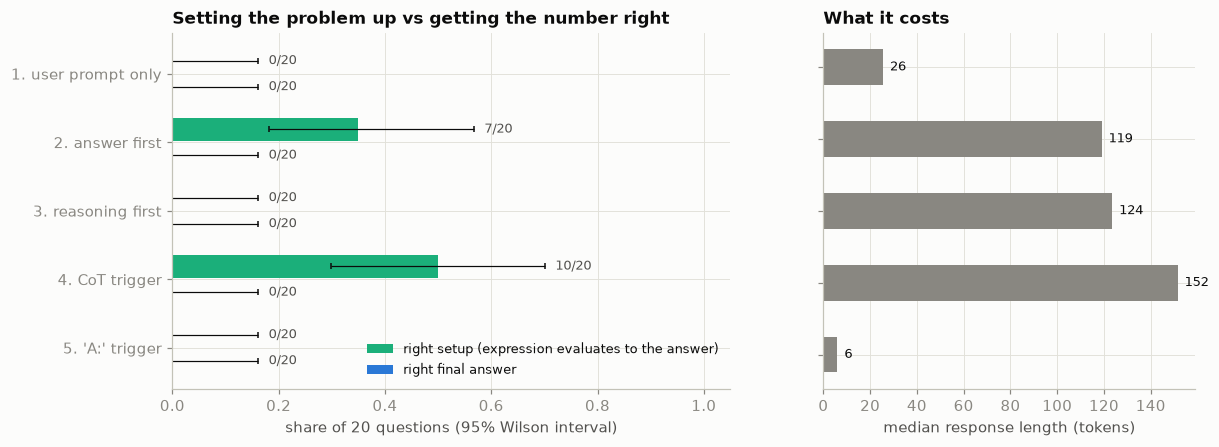

In [23]:
# 95% Wilson intervals: with 20 questions, how precise is each rate?
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


stats = sweep.groupby("strategy").agg(setup=("setup", "sum"), correct=("correct", "sum"), n=("correct", "size"),
                                      tokens=("tokens", "median")).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
y = np.arange(len(stats))[::-1]
for offset, col, color, label in [(0.19, "setup", AQUA, "right setup (expression evaluates to the answer)"),
                                  (-0.19, "correct", BLUE, "right final answer")]:
    rate = stats[col] / stats.n
    low, high = zip(*[wilson(k, n) for k, n in zip(stats[col], stats.n)])
    axes[0].barh(y + offset, rate, height=0.34, color=color, label=label)
    axes[0].errorbar(rate, y + offset, xerr=[rate - np.array(low), np.array(high) - rate], fmt="none", ecolor=INK, capsize=2, lw=0.8)
    for yi, k, n, hi in zip(y + offset, stats[col], stats.n, high):
        axes[0].text(hi + 0.02, yi, f"{k}/{n}", va="center", fontsize=8.5, color=SECONDARY)
axes[0].set_yticks(y); axes[0].set_yticklabels(stats.strategy); axes[0].set_xlim(0, 1.05)
axes[0].set_xlabel("share of 20 questions (95% Wilson interval)")
axes[0].set_title("Setting the problem up vs getting the number right")
axes[0].legend(loc="lower right", fontsize=8.5)
axes[1].barh(y, stats.tokens, color=MUTED, height=0.5)
for yi, t in zip(y, stats.tokens):
    axes[1].text(t + 3, yi, f"{t:.0f}", va="center", fontsize=8.5)
axes[1].set_yticks(y); axes[1].set_yticklabels([])
axes[1].set_xlabel("median response length (tokens)"); axes[1].set_title("What it costs")
plt.savefig("assets/6.1-cot-accuracy.png")
plt.show()

In [ ]:
# Paired test: the same 20 questions are used for every prompt, so compare the CoT trigger with each other prompt
# question by question (exact McNemar test: only the questions where exactly one of the two got the setup right count).
from scipy.stats import binomtest

by_question = sweep.pivot(index="variant", columns="strategy", values="setup")
cot = by_question["4. CoT trigger"]
rows = []
for other in by_question.columns.drop("4. CoT trigger"):
    only_cot, only_other = int((cot & ~by_question[other]).sum()), int((~cot & by_question[other]).sum())
    p = binomtest(only_cot, only_cot + only_other, 0.5).pvalue if only_cot + only_other else 1.0
    rows.append((other, only_cot, only_other, round(p, 4)))
pd.DataFrame(rows, columns=["compared with", "only CoT right", "only the other right", "exact McNemar p"])

,compared with,only CoT right,only the other right,exact McNemar p
0,1. user prompt only,10,0,0.0020
1,2. answer first,6,3,0.5078
2,3. reasoning first,10,0,0.0020
3,5. 'A:' trigger,10,0,0.0020


In [24]:
# Where do the wrong answers come from? Show one wrong response per strategy, if any.
for name, group in sweep.groupby("strategy"):
    wrong = group[~group.correct]
    if len(wrong):
        w = wrong.iloc[0]
        print(f"=== {name}: {len(wrong)} wrong. Example: answered {w.answer}, true {w.truth}\n{w.text[:700]}\n")

=== 1. user prompt only: 20 wrong. Example: answered 10000.0, true 3838
10000

=== 2. answer first: 20 wrong. Example: answered 3955.0, true 3838
1) The user prompt can be used for 8192 - 2048 - 91 - 2194 = 3955 tokens.
2) The reasoning is that the system prompt uses 91 tokens, the chain of thought trigger uses 21 tokens, and the conversational history uses 2194 tokens. Therefore, the user prompt can be used for 8192 - 2048 - 91 - 2194 = 3955 tokens.

=== 3. reasoning first: 20 wrong. Example: answered 5906.0, true 3838
1) The system prompt uses 91 tokens, the chain of thought trigger uses 21 tokens, and the conversational history uses 2194 tokens. Therefore, the total number of tokens used for the system prompt, chain of thought trigger, and conversational history is 2286 tokens.
2) The user prompt can use 8192 - 2286 = 5906 tokens.

=== 4. CoT trigger: 20 wrong. Example: answered 3717.0, true 3838
 1. The context window is 8192 tokens. 2. We are reserving 2048 tokens for the LLM resp

**Result on 20 variants.**

1. **Final answer: 0 out of 20 for every prompt**, 0 out of 100 in total. Even when it writes the right expression, Qwen 2 1.5B cannot reliably subtract four or five numbers of 2 to 5 digits. With 0/20 the 95% Wilson interval is 0% to 16%.
2. **Setup: the CoT trigger 10/20, answer first 7/20, the other three 0/20.** The CoT trigger against prompt only, reasoning first and `A:` is 10 questions to 0 each time, exact McNemar $p = 0.002$. Against answer first it is 6 to 3, $p = 0.51$: with 20 questions these two cannot be told apart.
3. **Why answer first scores at all.** The model does not obey "answer first". In 4 of its 7 right setups the expression is on the first line, written before the number (`can be used for 8192 - 512 - 566 - 13 - 1254 = 3403`). That is reasoning before the answer in miniature, inside the line that was supposed to hold only the answer.
4. **Why reasoning first scores 0.** The system prompt gave the response a two-step structure, but not a useful one. The model spends step 1 restating the question, then does a two-stage calculation (add up the parts, subtract the total) in which it forgets one part or mis-adds, for example `8192 - 2286 = 5906` with the 2,048-token reservation left out.
5. **How CoT fails.** In 8 of its 10 wrong setups the model lists the parts one per line and simply skips the system prompt. In the right ones it is usually close but wrong on the final subtraction (3,717 for 3,838).
6. **Cost.** The CoT trigger produces the longest responses: a median of 152 tokens, against 26 for the bare prompt and 6 for `A:`. That is about 6 times the output tokens.

# Summary

1. **The course demo's triggers never reached the model.** The trigger was appended to a string that was not sent. Building the chat template by hand and writing the trigger at the start of the assistant's turn fixes it, and the raw and chat endpoints giving the same greedy answer confirms the template is right.
2. **On a 1.5B model, the prompt changes how the problem is set up, not whether the answer is right.** "Let's think step by step" made the model write the correct equation for half the questions, against none with the plain prompt ($p = 0.002$), but no prompt produced a single correct number in 100 tries. Writing the reasoning first helps only if the model can then do each step.
3. **Order matters, and small models do not follow format instructions reliably.** The answer-first prompt was partly ignored: the model wrote the expression before the number anyway, which is why it set up 7 of 20 correctly. An explicit format in the system prompt (prompt 3) did worse than the four-word trigger (prompt 4).
4. **The practical fix is to let code do the arithmetic.** The setup score in this notebook already does it: Python evaluates the expression the model wrote. Turned into a method, that is program-aided reasoning (PAL, Gao et al., 2022; Program of Thoughts, Chen et al., 2022): the model writes the calculation, an interpreter runs it. Here it would turn the CoT trigger's 10 right setups into 10 right answers.
5. **Reasoning costs tokens.** About 6 times the output of a plain answer, which matters at scale and for latency.

**Limitations.**

- One model, one task family, 20 variants, greedy decoding. Differences of a few questions are within the 95% intervals shown and should not be over-read.
- $T = 0$ is not bit-exact on a shared server: two identical runs gave the CoT trigger 8 and 10 right setups (requests are batched with other users', and the floating-point sums change with the batch). The figures and tables come from one run, which the sweep cell saves to `data/6.1-sweep.csv` (not committed; re-running the notebook recreates it).
- The setup score accepts any expression in the response that evaluates to the answer, including one the model writes and then does not use.
- The scoring rule for answer-first (the first new number) is a reasonable reading of "the answer it committed to", but a model that restates an input number as its answer would be scored as having given no answer.
- Qwen 2 1.5B is a small model. Larger instruction-tuned models often reason step by step without being asked, and current reasoning models do it internally whatever the prompt says, so the gap between prompts is expected to be smaller for them.

**References.**

- Wei et al. (2022). *Chain-of-Thought Prompting Elicits Reasoning in Large Language Models.* [arXiv:2201.11903](https://arxiv.org/abs/2201.11903)
- Kojima et al. (2022). *Large Language Models are Zero-Shot Reasoners.* [arXiv:2205.11916](https://arxiv.org/abs/2205.11916)
- Gao et al. (2022). *PAL: Program-aided Language Models.* [arXiv:2211.10435](https://arxiv.org/abs/2211.10435)
- Chen et al. (2022). *Program of Thoughts Prompting: Disentangling Computation from Reasoning for Numerical Reasoning Tasks.* [arXiv:2211.12588](https://arxiv.org/abs/2211.12588)
- Yang et al. (2024). *Qwen2 Technical Report.* [arXiv:2407.10671](https://arxiv.org/abs/2407.10671)
- Together AI, completions API. [docs.together.ai/reference/completions-1](https://docs.together.ai/reference/completions-1)